# Titanic Passenger Data: Ordinal Encoding Analysis

This notebook walks through ordinal encoding using `titanic.csv`. We will inspect the data, visualize survival patterns, identify which variables truly have an order, encode passenger class and age bands, and keep the survival outcome separate from predictors.

**Ordinal encoding** assigns integer codes to categories that have a meaningful order. In this analysis:

- Passenger class follows **1st < 2nd < 3rd** in class rank.
- Age bands are defined as **child < adult < senior** for a simple illustrative grouping. The band boundaries are analysis choices, not universal definitions.
- Sex and embarkation port are nominal categories, so they are one-hot encoded instead of being given arbitrary ranks.

The file uses `?` to represent missing values. The output is an educational preprocessing example and does not claim that the encoding alone predicts survival accurately.


## 1. Import tools and load the CSV

We tell pandas to treat `?` as missing. This makes data quality checks and plots behave correctly. The source file is expected beside this notebook.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

sns.set_theme(style="whitegrid", context="notebook", palette="Set2")
DATA_PATH = Path("titanic.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Expected titanic.csv beside this notebook: {DATA_PATH.resolve()}")
df = pd.read_csv(DATA_PATH, na_values=["?"])
print(f"Dataset size: {df.shape[0]:,} passengers × {df.shape[1]} columns")
display(df.head())

Dataset size: 1,309 passengers × 14 columns


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


## 2. Understand the columns and missing data

The file includes passenger demographics, ticket details, survival outcome, and some post-event fields. `survived` is the target (0 = no, 1 = yes). `boat` and `body` are known only after the incident, so they must not be used as predictors of survival; doing so would leak the answer. `name`, `ticket`, `cabin`, and `home.dest` are identifiers or high-cardinality text and need separate feature-engineering decisions.

We check types, missingness, and unique values before selecting features.

In [2]:
display(df.dtypes.to_frame("dtype"))
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(1)
}).sort_values("missing_percent", ascending=False)
display(missing_summary)
print("Duplicate rows:", df.duplicated().sum())
print("Outcome counts:")
display(df["survived"].value_counts(dropna=False).sort_index().rename(index={0: "Did not survive", 1: "Survived"}).to_frame("passengers"))

,dtype
pclass,int64
survived,int64
name,object
sex,object
age,float64
sibsp,int64
parch,int64
ticket,object
fare,float64
cabin,object


,missing_count,missing_percent
body,1188,90.8
cabin,1014,77.5
boat,823,62.9
home.dest,564,43.1
age,263,20.1
embarked,2,0.2
fare,1,0.1
pclass,0,0.0
survived,0,0.0
name,0,0.0


Duplicate rows: 0
Outcome counts:


,passengers
survived,
Did not survive,809
Survived,500


## 3. Explore survival and passenger groups

The first chart shows the outcome balance. The next charts compare survival proportions across passenger class, sex, and embarkation port. These are descriptive associations in this dataset; they do not establish cause and effect.

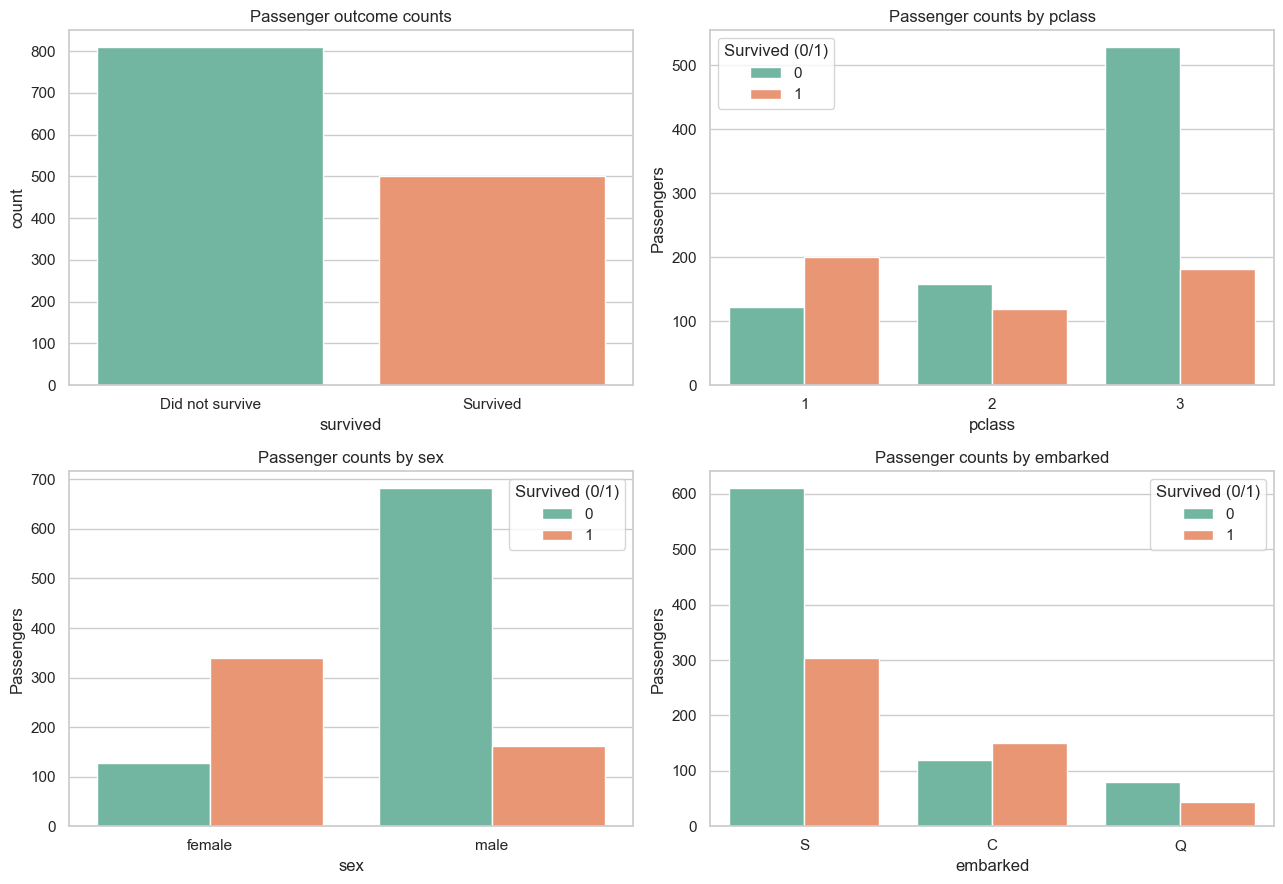

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.countplot(data=df, x="survived", hue="survived", legend=False, ax=axes[0, 0])
axes[0, 0].set_title("Passenger outcome counts")
axes[0, 0].set_xticks([0, 1], ["Did not survive", "Survived"])

for ax, col in zip(axes.flat[1:], ["pclass", "sex", "embarked"]):
    sns.countplot(data=df, x=col, hue="survived", ax=ax)
    ax.set_title(f"Passenger counts by {col}")
    ax.set_ylabel("Passengers")
    ax.legend(title="Survived (0/1)")
plt.tight_layout()
plt.show()

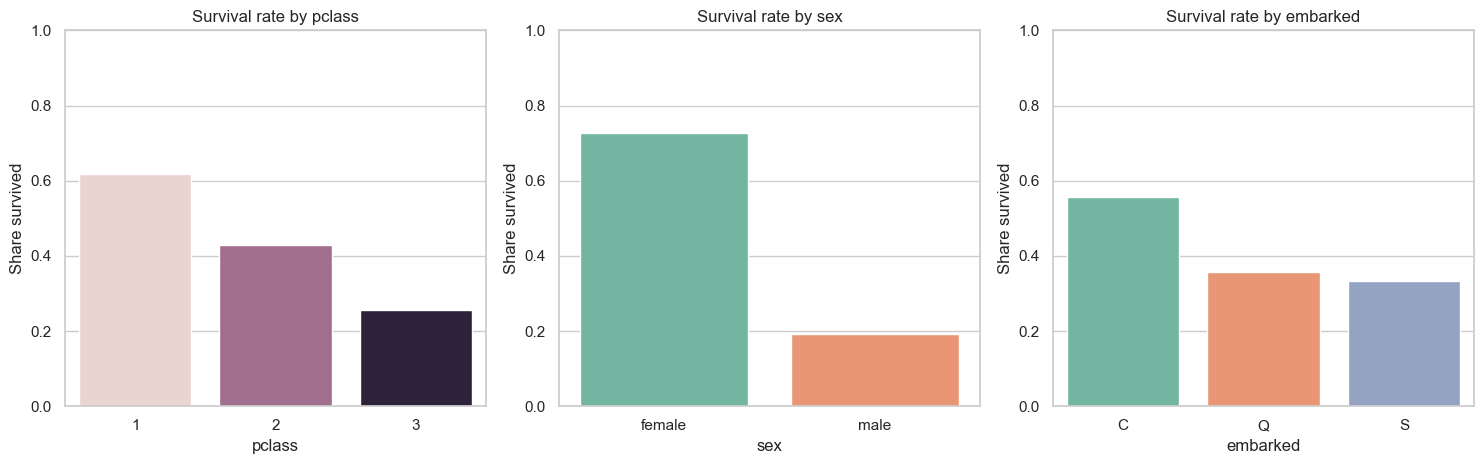

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, col in zip(axes, ["pclass", "sex", "embarked"]):
    rate = df.groupby(col, dropna=False)["survived"].mean().rename("survival_rate").reset_index()
    sns.barplot(data=rate, x=col, y="survival_rate", hue=col, legend=False, ax=ax)
    ax.set_title(f"Survival rate by {col}")
    ax.set_ylim(0, 1)
    ax.set_ylabel("Share survived")
plt.tight_layout()
plt.show()

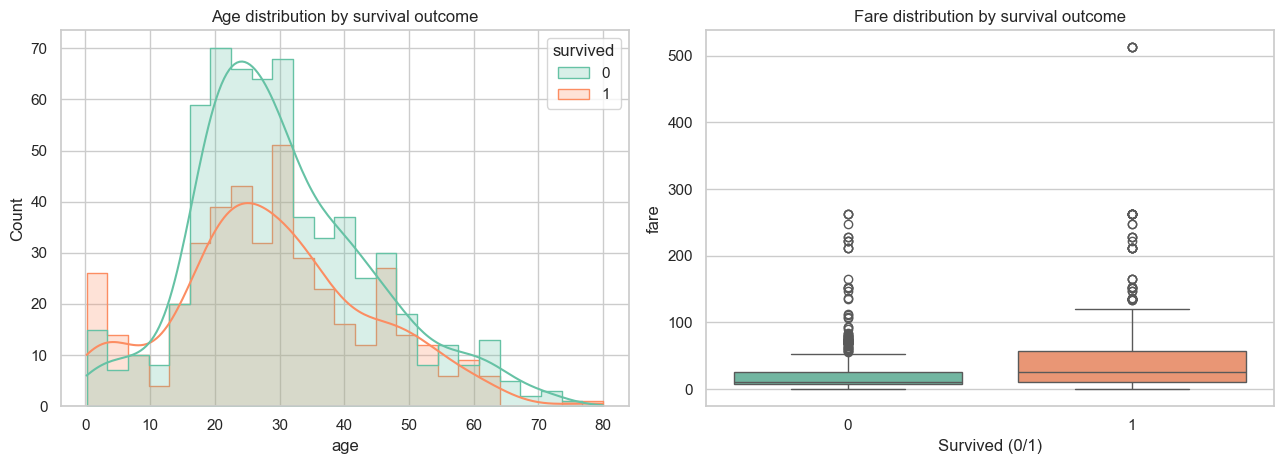

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.histplot(data=df, x="age", hue="survived", bins=25, kde=True, element="step", common_norm=False, ax=axes[0])
axes[0].set_title("Age distribution by survival outcome")
sns.boxplot(data=df, x="survived", y="fare", hue="survived", legend=False, ax=axes[1])
axes[1].set_title("Fare distribution by survival outcome")
axes[1].set_xlabel("Survived (0/1)")
plt.tight_layout()
plt.show()

## 4. Choose appropriate encodings

| Variable | Meaning | Treatment | Reason |
|---|---|---|---|
| `pclass` | Passenger class 1, 2, 3 | Ordinal code 0, 1, 2 | Classes have a clear rank order; code increases from 1st to 3rd |
| `age_group` | Child, adult, senior | Ordinal code 0, 1, 2 | We define ordered age bands for this demonstration |
| `sex` | Female, male | One-hot | No meaningful numeric rank |
| `embarked` | Port code | One-hot | Port labels are nominal |
| `survived` | Outcome | Keep separate as target | Must not enter feature matrix |

Ordinal codes indicate order, not equal gaps. `pclass` code 2 is not necessarily twice the class rank of code 1. The age grouping discards detail and depends on the chosen cut points. We will preserve raw age separately in a different modeling design; here we use age group to demonstrate ordinal encoding.

## 5. Prepare an analysis table and handle missing values

We select columns needed for this demonstration. Missing age is kept as missing until it is assigned to the explicit `Unknown` group. Missing embarkation values become an `Unknown` nominal category. We exclude `boat`, `body`, name, ticket, cabin, and destination from this simple example for the reasons described above.

In [6]:
analysis = df[["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]].copy()
analysis["age_group"] = pd.cut(
    analysis["age"], bins=[-np.inf, 17, 59, np.inf],
    labels=["Child", "Adult", "Senior"], right=True
).astype("object")
analysis["age_group"] = analysis["age_group"].fillna("Unknown")
analysis["sex"] = analysis["sex"].fillna("Unknown")
analysis["embarked"] = analysis["embarked"].fillna("Unknown")
print("Age-band counts (including missing ages):")
display(analysis["age_group"].value_counts().reindex(["Child", "Adult", "Senior", "Unknown"]).rename("passengers").to_frame())
display(analysis.head())

Age-band counts (including missing ages):


,passengers
age_group,
Child,154
Adult,852
Senior,40
Unknown,263


,survived,pclass,sex,age,sibsp,parch,fare,embarked,age_group
0,1,1,female,29.0000,0,0,211.3375,S,Adult
1,1,1,male,0.9167,1,2,151.5500,S,Child
2,0,1,female,2.0000,1,2,151.5500,S,Child
3,0,1,male,30.0000,1,2,151.5500,S,Adult
4,0,1,female,25.0000,1,2,151.5500,S,Adult


## 6. Visualize the ordered age groups

The bands used here are: age ≤ 17 is Child, 18–59 is Adult, and age ≥ 60 is Senior. Missing ages are Unknown, not silently assigned to one of the ranks. The age group plot shows the sample counts and the observed survival rates.

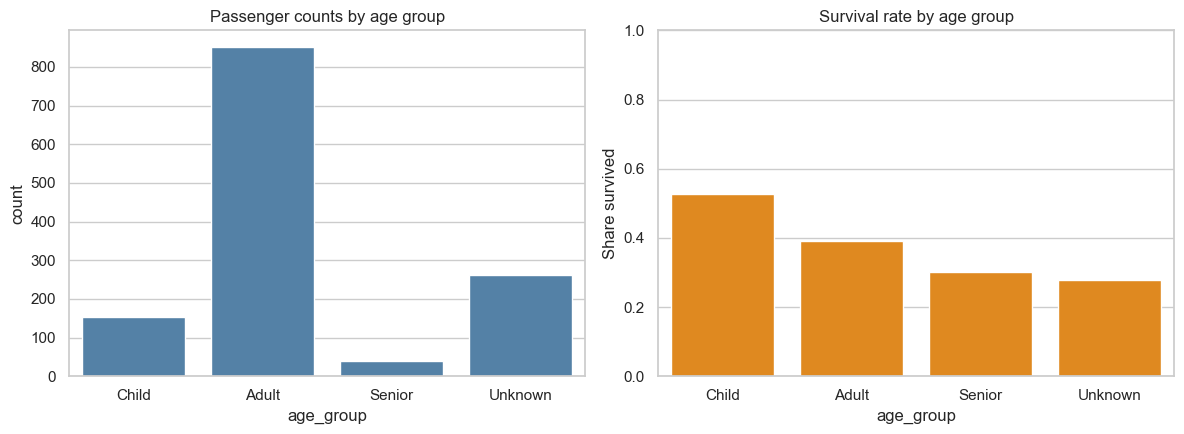

In [7]:
age_order = ["Child", "Adult", "Senior", "Unknown"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.countplot(data=analysis, x="age_group", order=age_order, color="steelblue", ax=axes[0])
axes[0].set_title("Passenger counts by age group")
rate = analysis.groupby("age_group", observed=False)["survived"].mean().reindex(age_order).rename("survival_rate").reset_index()
sns.barplot(data=rate, x="age_group", y="survival_rate", order=age_order, color="darkorange", ax=axes[1])
axes[1].set_title("Survival rate by age group")
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Share survived")
plt.tight_layout()
plt.show()

## 7. Split train and test rows before fitting encoders

We separate `survived` from predictors and reserve a stratified test subset. The ordinal category ordering is defined by meaning. The nominal encoder will be fit on training data and reused unchanged on test data.

In [8]:
target = analysis["survived"].astype(int)
predictor_cols = ["pclass", "age_group", "sex", "embarked", "sibsp", "parch", "fare"]
X = analysis[predictor_cols].copy()
X["pclass"] = X["pclass"].astype("Int64").astype("string")

X_train, X_test, y_train, y_test = train_test_split(
    X, target, test_size=0.25, random_state=42, stratify=target
)
print(f"Training passengers: {len(X_train):,} | Test passengers: {len(X_test):,}")
print("Survival share — train:", round(y_train.mean(), 3))
print("Survival share — test:", round(y_test.mean(), 3))

Training passengers: 981 | Test passengers: 328
Survival share — train: 0.382
Survival share — test: 0.381


## 8. Ordinal encode passenger class and age group

The declared category lists control the output code order. For passenger class, 1st class receives 0, 2nd class 1, and 3rd class 2: a larger code means a lower passenger class rank. For age group, Child=0, Adult=1, Senior=2. Unknown age is handled as an explicit category at the end; missing age is not treated as a higher or lower age.

In [9]:
pclass_order = ["1", "2", "3"]
age_group_order = ["Child", "Adult", "Senior", "Unknown"]
ordinal_encoder = OrdinalEncoder(
    categories=[pclass_order, age_group_order],
    dtype=np.int64, handle_unknown="use_encoded_value", unknown_value=-1
)
ordinal_cols = ["pclass", "age_group"]
train_ord = pd.DataFrame(
    ordinal_encoder.fit_transform(X_train[ordinal_cols]),
    columns=["pclass_ordinal", "age_group_ordinal"], index=X_train.index
)
test_ord = pd.DataFrame(
    ordinal_encoder.transform(X_test[ordinal_cols]),
    columns=["pclass_ordinal", "age_group_ordinal"], index=X_test.index
)
display(train_ord.head())

,pclass_ordinal,age_group_ordinal
1216,2,3
819,2,3
1286,2,1
1280,2,1
761,2,0


## 9. One-hot encode nominal variables

We one-hot encode `sex` and `embarked` because their categories are labels without an intrinsic order. `handle_unknown="ignore"` lets the transformation continue if test data contains a nominal category not observed during training. We also keep the numeric household counts and fare as numeric values.

In [10]:
nominal_cols = ["sex", "embarked"]
nominal_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.int64)
train_nom_array = nominal_encoder.fit_transform(X_train[nominal_cols])
test_nom_array = nominal_encoder.transform(X_test[nominal_cols])
nominal_names = nominal_encoder.get_feature_names_out(nominal_cols)
train_nom = pd.DataFrame(train_nom_array, columns=nominal_names, index=X_train.index)
test_nom = pd.DataFrame(test_nom_array, columns=nominal_names, index=X_test.index)
print("One-hot columns:", nominal_names.tolist())
display(train_nom.head())

One-hot columns: ['sex_female', 'sex_male', 'embarked_C', 'embarked_Q', 'embarked_S']


,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
1216,1,0,0,1,0
819,1,0,0,1,0
1286,1,0,1,0,0
1280,0,1,0,0,1
761,0,1,0,0,1


## 10. Build model-ready feature tables

The resulting table combines ordinal codes, one-hot indicators, and numeric predictors. `survived` remains outside these tables as `y_train` and `y_test`. We use the same column order for both subsets.

In [11]:
numeric_cols = ["sibsp", "parch", "fare"]
X_train_encoded = pd.concat([train_ord, train_nom, X_train[numeric_cols]], axis=1).sort_index()
X_test_encoded = pd.concat([test_ord, test_nom, X_test[numeric_cols]], axis=1).sort_index()
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns)
print("Encoded training feature shape:", X_train_encoded.shape)
print("Encoded test feature shape:", X_test_encoded.shape)
display(X_train_encoded.head())

Encoded training feature shape: (981, 10)
Encoded test feature shape: (328, 10)


,pclass_ordinal,age_group_ordinal,sex_female,sex_male,embarked_C,embarked_Q,embarked_S,sibsp,parch,fare
1,0,0,0,1,0,0,1,1,2,151.5500
2,0,0,1,0,0,0,1,1,2,151.5500
4,0,1,1,0,0,0,1,1,2,151.5500
6,0,2,1,0,0,0,1,1,0,77.9583
7,0,1,0,1,0,0,1,0,0,0.0000


## 11. Inspect mappings and visualize encoded ranks

The mapping table helps prevent confusion about what each integer means. The following chart shows how passenger class counts are represented by the ordinal values. These codes preserve rank order, but their numeric gaps should not be interpreted as measured distances.

,original category,encoded value,feature
0,1,0,pclass
1,2,1,pclass
2,3,2,pclass
3,Child,0,age_group
4,Adult,1,age_group
5,Senior,2,age_group
6,Unknown,3,age_group


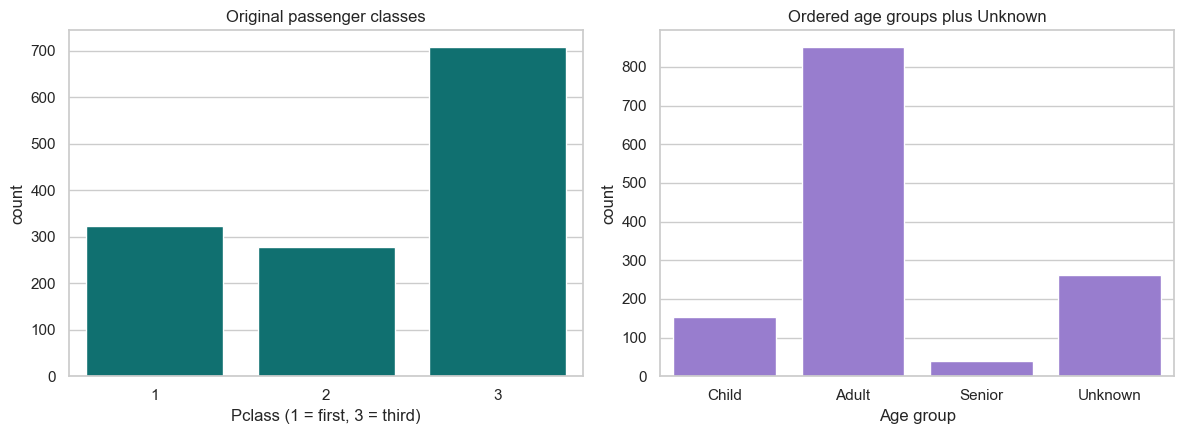

In [12]:
mapping_table = pd.DataFrame({
    "original category": pclass_order + age_group_order,
    "encoded value": list(range(len(pclass_order))) + list(range(len(age_group_order))),
    "feature": ["pclass"] * len(pclass_order) + ["age_group"] * len(age_group_order)
})
display(mapping_table)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.countplot(data=analysis, x="pclass", order=[1, 2, 3], color="teal", ax=axes[0])
axes[0].set_title("Original passenger classes")
axes[0].set_xlabel("Pclass (1 = first, 3 = third)")
sns.countplot(data=analysis, x="age_group", order=age_group_order, color="mediumpurple", ax=axes[1])
axes[1].set_title("Ordered age groups plus Unknown")
axes[1].set_xlabel("Age group")
plt.tight_layout()
plt.show()

## 12. Validate and review encoded examples

We check that train and test feature names match, all feature values are numeric, and the target contains only 0/1 values. Then we look at raw categories next to their encoded representation.

In [13]:
assert X_train_encoded.columns.equals(X_test_encoded.columns)
assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in X_train_encoded.dtypes)
assert set(y_train.unique()) <= {0, 1}
print("Checks passed: matching numeric feature tables and separate binary target.")
examples = X_train[["pclass", "age_group", "sex", "embarked"]].join(
    X_train_encoded[["pclass_ordinal", "age_group_ordinal"]]
).join(y_train.rename("survived_target"))
display(examples.head(12))

Checks passed: matching numeric feature tables and separate binary target.


,pclass,age_group,sex,embarked,pclass_ordinal,age_group_ordinal,survived_target
1216,3,Unknown,female,Q,2,3,1
819,3,Unknown,female,Q,2,3,1
1286,3,Adult,female,C,2,1,1
1280,3,Adult,male,S,2,1,0
761,3,Child,male,S,2,0,0
746,3,Adult,male,Q,2,1,1
1297,3,Unknown,male,S,2,3,0
25,1,Adult,male,C,0,1,0
750,3,Adult,male,S,2,1,0
642,3,Child,male,S,2,0,0


## 13. Interpretation and limitations

- Ordinal encoding is suitable for categories with a defensible order. Passenger class and the defined age groups are examples, but the exact age cut points are a modeling decision.
- Encoding age into bands loses information compared with using continuous age. Treat this as a teaching example; compare against a strategy that imputes missing age and retains it as a numeric feature.
- The `Unknown` age group is a missingness indicator category. Its code is not an age rank.
- Sex and embarkation port are nominal, so one-hot encoding avoids inventing an order.
- `boat` and `body` are omitted because they reveal information after the survival event. The target `survived` is also excluded from predictors.
- For cross-validation, fit imputers and encoders inside each fold using a scikit-learn `Pipeline` or `ColumnTransformer`.
- Visualized survival proportions describe this dataset and should not be interpreted as causal effects or guaranteed patterns in other populations.

### Summary

We explored Titanic passenger records and missingness, compared survival patterns visually, defined and documented two ordinal mappings, one-hot encoded nominal fields, and built train/test feature tables with the outcome kept separate. `X_train_encoded` / `X_test_encoded` are the predictors; `y_train` / `y_test` are survival labels.
